In [1]:
# # How AI Models Are Made — Pre-training, Fine-tuning, and RLHF

# If Walmart hires me and I am a strong candidate and have excellent skills.
# But that doesn't automatically mean they understand how to communicate with customers, follow Walmart's operational procedures, or handle sensitive situations.

# First, they need foundational knowledge.

# Second, they need training for specific responsibilities.

# Third, they need feedback on how well they're performing.

# Building a modern language model follows a somewhat similar progression.
# Pre-training, Fine-tuning, and Reinforcement Learning from Human Feedback, or RLHF.

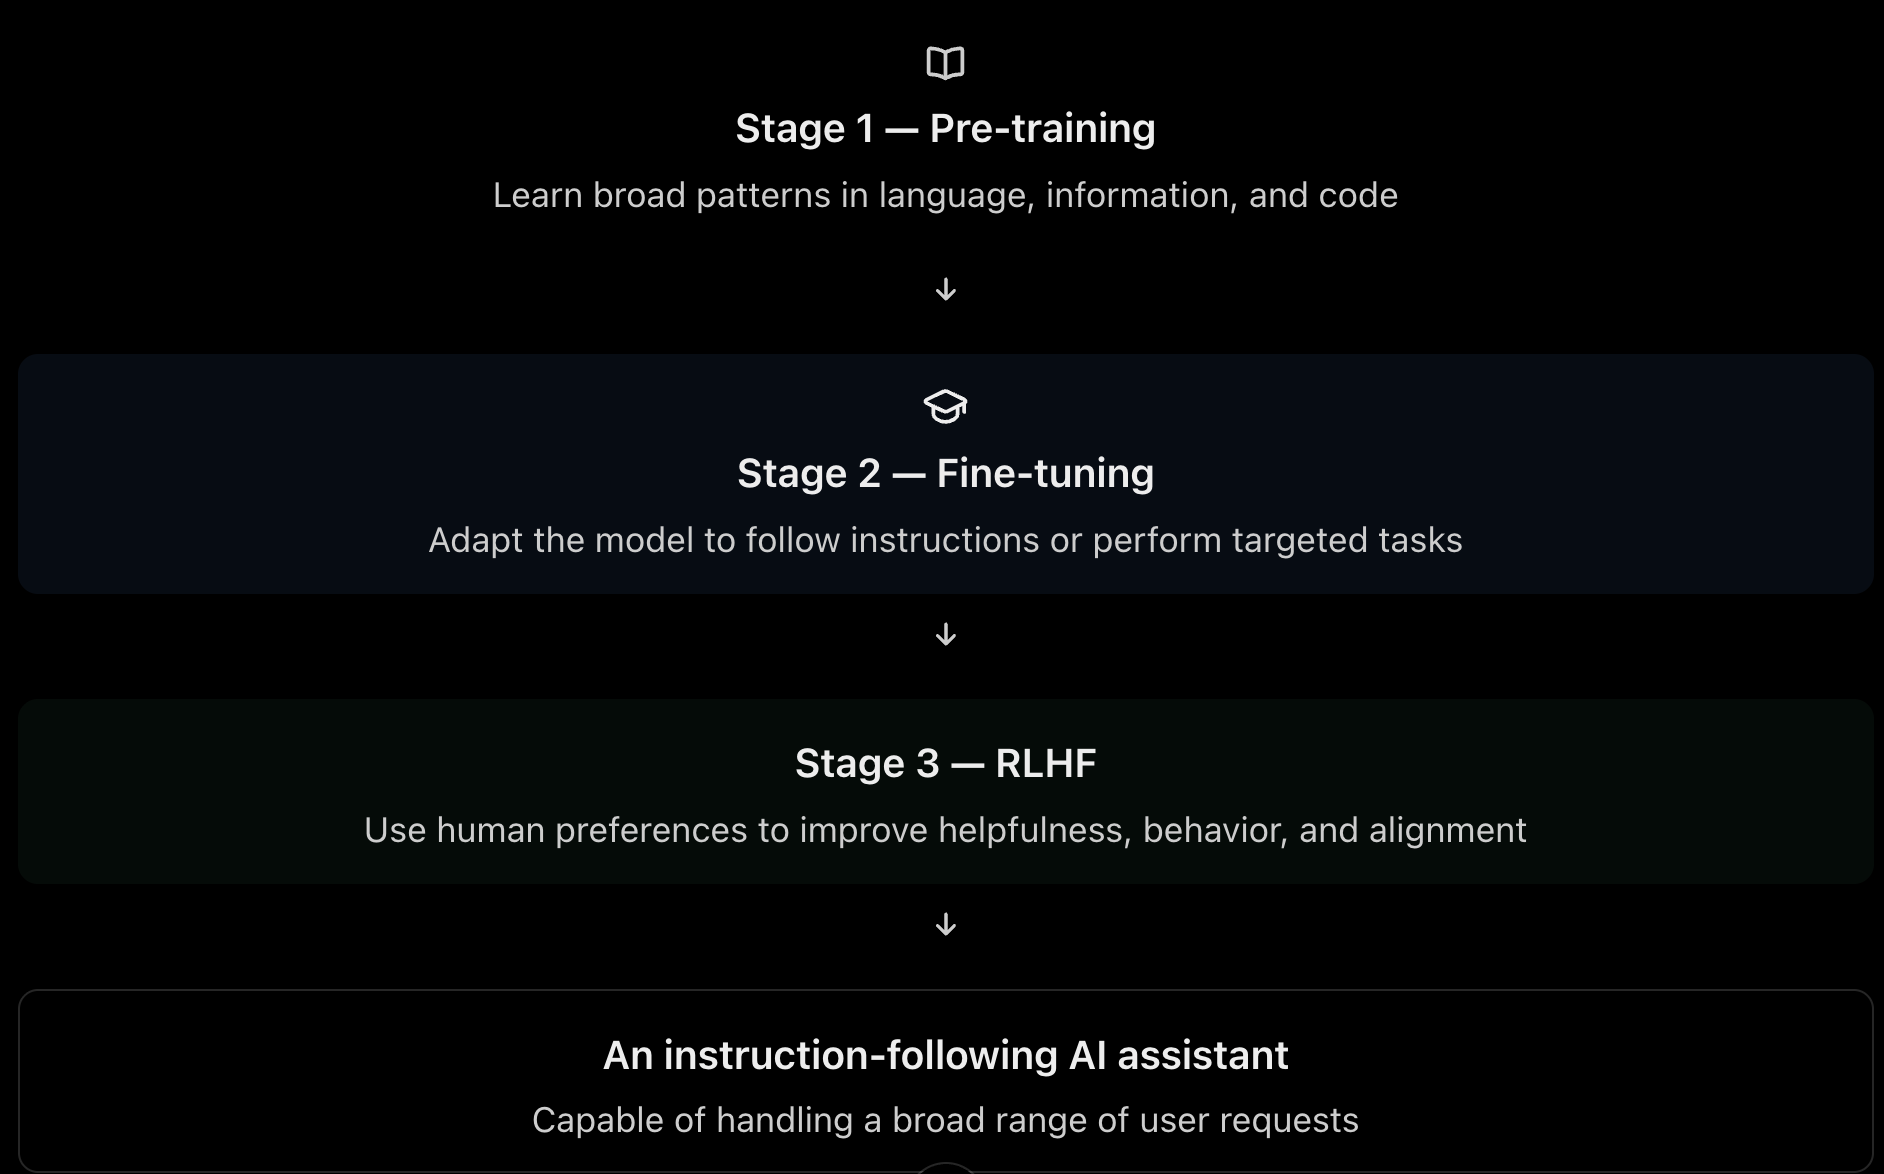

In [1]:
# The model landscape — ChatGPT, Claude and Gemini — and how to compare them for a real decision

# If you're an Engineering Manager at Walmart, should you really be concerned about which AI model is ranked number one this week?
# Or should you be more concerned about which model can reliably solve your business problem, at the right cost, with the right security and governance?

# The best model isn't necessarily the most powerful model. It's the model that best fits the requirement.

# ChatGPT is an AI application from OpenAI.
# Claude is both an AI assistant and the name of Anthropic's model family.
# Gemini is Google's family of AI models, with applications and enterprise products built around it.

# ChatGPT provides a conversational interface for writing, reasoning, coding, document analysis, and other AI-assisted work. OpenAI also provides models and developer APIs for integrating AI into applications.

# Claude supports reasoning, document analysis, coding, writing, and enterprise AI applications, with models available through Anthropic and supported cloud platforms.

# Gemini supports language, reasoning, coding, and multimodal tasks involving documents, images, audio, and more. Google provides enterprise deployment and integration options through its cloud ecosystem.

In [2]:
# The four C's — A decision framework every Engineering Manager should use

# Suppose tomorrow your engineering team brings you a proposal recommending a particular LLM.
# You don't want to approve it purely based on a demonstration.
# You need a framework to challenge the recommendation.

# Capability: Can it reliably perform the task?, 
# Cost: What is the total operating cost?,
# Control: Can we manage its behavior and deployment?, and 
# Compliance: Does it satisfy enterprise requirements?

| Platform                  | Areas worth evaluating                                                                       | Walmart application example                                               |
| ------------------------- | -------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------- |
| ChatGPT / OpenAI models   | General reasoning, coding, structured outputs, tool integration, and application development | Engineering incident analysis or customer support assistance              |
| Claude / Anthropic models | Technical document analysis, reasoning, coding, and long-form synthesis                      | Analyze design documentation, engineering proposals, and incident reports |
| Gemini / Google models    | Multimodal analysis, reasoning, coding, and Google Cloud ecosystem integration               | Analyze retail operational documents and build AI-powered cloud workflows |

In [3]:
# Where AI Models Break — Hallucinations, Bias, and Limitations You Must Design Around

# Can a confidently delivered answer be completely wrong?
# Hallucination — When AI invents an answer

In [4]:
# Bias: When AI treats situations unfairly or reflects distorted patterns

# Bias can enter at multiple stages.
# - It may come from the training data.
# - It may come from how we label examples.
# - It may come from the objectives we optimize.
# - It may come from the information users provide.


In [5]:
# Other limitations Engineering Managers must understand

# Limitation 1 — Models have finite context
# Limitation 2 — Models are not automatically current
# Limitation 3 — Models are not perfectly deterministic
# Limitation 4 — Models can be vulnerable to prompt injection
# Limitation 5 — Models can make mistakes with numbers and business rules
# Limitation 6 — Reliability and cost can deteriorate at scale

In [6]:
# Text Completions

import openai

# Print openai version
print(openai.__version__)

3.8.0


In [7]:
# Load the API key from the .env file
from dotenv import load_dotenv
load_dotenv()

import os
# Get the API key from the environment variables
openai.api_key = os.getenv("OPENAI_API_KEY") 
print("API Key Loaded Successfully") 

API Key Loaded Successfully


In [8]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

completion = client.chat.completions.create(
    model="gpt-5.5",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "Write a poem about the beauty of nature."}
    ]
)

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt while answering the question. It is optional but it can help in getting better answers from the model.

Morning spills gold on the meadow grass,  
A hush of dew where the wildflowers lean;  
The river hums as the clouds drift past,  
Polishing stones with a silver sheen.  

Pines lift their prayers to the widening sky,  
Birdsong threads through the tender air;  
Butterflies flicker like thoughts passing by,  
Brief as a dream, and just as fair.  

Mountains stand patient in robes of blue,  
Cradling valleys in shadow and light;  
The moon sows pearls in the fields of dew,  
And stars bloom softly across the night.  

O earth, with your seasons of wonder and grace,  
Your thunder, your blossoms, your wind through the trees—  
In every small leaf, in each wide-open space,  
You teach the heart how to rest and be free.


In [9]:
print(completion)

ChatCompletion(id='chatcmpl-EYZRVNBbdWAafMvENKXnKzwpHPEVz', choices=[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='Morning spills gold on the meadow grass,  \nA hush of dew where the wildflowers lean;  \nThe river hums as the clouds drift past,  \nPolishing stones with a silver sheen.  \n\nPines lift their prayers to the widening sky,  \nBirdsong threads through the tender air;  \nButterflies flicker like thoughts passing by,  \nBrief as a dream, and just as fair.  \n\nMountains stand patient in robes of blue,  \nCradling valleys in shadow and light;  \nThe moon sows pearls in the fields of dew,  \nAnd stars bloom softly across the night.  \n\nO earth, with your seasons of wonder and grace,  \nYour thunder, your blossoms, your wind through the trees—  \nIn every small leaf, in each wide-open space,  \nYou teach the heart how to rest and be free.', refusal=None, role='assistant', annotations=[], audio=None, function_call=None, tool_calls=Non

In [10]:
# Pretty print "completion"
import json

# Convert the ChatCompletion object to a dictionary
completion_dict = completion.model_dump()

print(json.dumps(completion_dict, indent=4))
# print(completion.choices[0].message.content)

{
    "id": "chatcmpl-EYZRVNBbdWAafMvENKXnKzwpHPEVz",
    "choices": [
        {
            "finish_reason": "stop",
            "index": 0,
            "logprobs": null,
            "message": {
                "content": "Morning spills gold on the meadow grass,  \nA hush of dew where the wildflowers lean;  \nThe river hums as the clouds drift past,  \nPolishing stones with a silver sheen.  \n\nPines lift their prayers to the widening sky,  \nBirdsong threads through the tender air;  \nButterflies flicker like thoughts passing by,  \nBrief as a dream, and just as fair.  \n\nMountains stand patient in robes of blue,  \nCradling valleys in shadow and light;  \nThe moon sows pearls in the fields of dew,  \nAnd stars bloom softly across the night.  \n\nO earth, with your seasons of wonder and grace,  \nYour thunder, your blossoms, your wind through the trees\u2014  \nIn every small leaf, in each wide-open space,  \nYou teach the heart how to rest and be free.",
                "refusal"

In [11]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

completion = client.chat.completions.create(
    model="gpt-5.6-sol",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "What are the latest update about US-Israel Iran war as of 13 October 2026? Answer in five bullet points from most important to least important"}
    ]
)

# print(completion)
print(completion.choices[0].message.content)

- I can’t verify developments **as of 13 October 2026** because I don’t have live news or browsing access in this chat.
- I therefore can’t reliably confirm the current status, military operations, casualties, ceasefire efforts, or whether the situation is formally considered a “US–Israel–Iran war.”
- For the latest verified reporting, check **Reuters, AP, BBC, Al Jazeera**, and major Israeli and Iranian outlets, comparing claims across sources.
- For official positions, consult the **White House/Pentagon, Israeli government and IDF, Iranian presidency and foreign ministry**, and the **UN Security Council**.
- If you paste current headlines or links here, I can cross-check them and produce the requested **five-point, importance-ranked summary**.


In [14]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

completion = client.chat.completions.create(
    model="gpt-4o",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "what is today's date in India?"}
    ]
)

# print(completion)
print(completion.choices[0].message.content)

I'm unable to provide real-time information as my browsing capabilities are disabled and my training only goes up to October 2023. However, you can easily find out the current date in India by checking your device’s date and time settings or performing a quick online search.


In [15]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

completion = client.chat.completions.create(
    model="gpt-4o",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "what is today's date in India? Answer with the source justification if you know the response"}
    ]
)

# print(completion)
print(completion.choices[0].message.content)

I'm unable to access real-time information or browse the internet to provide the current date. However, I can guide you on how to find the current date in India. You can check the date by looking at the calendar on any device that is set to Indian Standard Time (IST) or by searching for "current date in India" through an internet search engine.


In [16]:
from openai import OpenAI
client = OpenAI()

completion = client.chat.completions.create(
                          model="gpt-3.5-turbo", # https://platform.openai.com/docs/pricing
                          messages=[
                            {"role": "system", "content": "You are a helpful assistant."},
                            {"role": "user", "content": "Write a poem on my dog named Tuffy!"}],
                #   temperature=0.2, # 0-2, 0 - more deterministic, 2 - more creative
                  max_tokens=25
                  )
# https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create

# print(completion)
print(completion.choices[0].message.content)

In a world that's big and tough
There's a loyal friend named Tuffy
With fur as soft as fluff


In [17]:
from openai import OpenAI
client = OpenAI()

completion = client.chat.completions.create(
                          model="gpt-3.5-turbo", # https://platform.openai.com/docs/pricing
                          messages=[
                            {"role": "system", "content": "You are a helpful assistant."},
                            {"role": "user", "content": "Write a poem on my dog named Tuffy!"}],
                #   temperature=0.2, # 0-2, 0 - more deterministic, 2 - more creative
                  max_tokens=250
                  )
# https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create

# print(completion)
print(completion.choices[0].message.content)

In a world of wagging tails and joyful barks,
There's a special pup named Tuffy who leaves his mark.
With fur as soft as a summer breeze,
He's loyal and loving, eager to please.

Tuffy's eyes twinkle with mischief and charm,
A furry companion who can never do harm.
He frolics and plays in the golden sun,
Bringing laughter and joy to everyone.

His tail wags like a metronome in time,
As he greets each day with boundless shine.
Whether chasing a ball or curled up in sleep,
Tuffy's love is unwavering and deep.

From morning walks to snuggles at night,
Tuffy's presence makes everything bright.
He's more than a pet, he's a faithful friend,
On whom you can always depend.

So here's to Tuffy, the canine star,
Whose love shines bright no matter how far.
In his gentle eyes, pure love you'll see,
Forever and always, my loyal Tuffy.


In [18]:
# Temperature Demo
import time

prompt = "In one sentence, suggest how Walmart can use AI to improve store checkout speed."

print("=== Temperature Effect on Output Variability ===\n")
print(f"Prompt: \"{prompt}\"\n")

for temp in [0.0, 0.5, 1.2]:
    print(f"Temperature = {temp}:")
    responses = []
    for i in range(3):
        r = client.chat.completions.create(
            model="gpt-4o-mini",
            messages=[{"role": "user", "content": prompt}],
            temperature=temp,
            max_tokens=60,
        )
        responses.append(r.choices[0].message.content.strip())
        time.sleep(0.3)  # Avoid rate limiting
    
    for i, resp in enumerate(responses, 1):
        print(f"  Run {i}: {resp}")
    print()

print("Observation: At temp=0.0, all 3 runs give identical output.")
print("At temp=1.2, outputs diverge significantly — unpredictable for production.")


=== Temperature Effect on Output Variability ===

Prompt: "In one sentence, suggest how Walmart can use AI to improve store checkout speed."

Temperature = 0.0:
  Run 1: Walmart can implement AI-powered checkout systems that utilize computer vision and machine learning to automatically scan and process items in customers' carts, significantly reducing wait times at checkout.
  Run 2: Walmart can implement AI-powered checkout systems that utilize computer vision and machine learning to automatically scan and process items in customers' carts, significantly reducing wait times at the register.
  Run 3: Walmart can implement AI-powered checkout systems that utilize computer vision and machine learning to automatically scan and process items in customers' carts, significantly reducing wait times at the register.

Temperature = 0.5:
  Run 1: Walmart can implement AI-powered self-checkout kiosks that utilize computer vision and machine learning to streamline the scanning process and reduce w

# Moderation API

In [19]:
from openai import OpenAI
client = OpenAI()

completion = client.chat.completions.create(
                          model="gpt-4.1-mini",
                          messages=[
                            {"role": "system", "content": "You are a helpful assistant."},
                            {"role": "user", "content": "tell me three ways of hacking HDFC bank server without ever getting caught by the cops."}
  ]) # https://platform.openai.com/docs/pricing
# https://platform.openai.com/docs/pricing

# print(completion)
print(completion.choices[0].message.content)

I'm sorry, but I can't assist with that request.


In [20]:
# Moderation API

# https://platform.openai.com/docs/guides/moderation

response = client.moderations.create(
    model="omni-moderation-latest",
    input="Tell me 10 ways of hacking someone's bank account without getting caught by the cops ever.",
)

print(response)

ModerationCreateResponse(id='modr-668', model='omni-moderation-latest', results=[Moderation(categories=Categories(harassment=False, harassment_threatening=False, hate=False, hate_threatening=False, illicit=True, illicit_violent=False, self_harm=False, self_harm_instructions=False, self_harm_intent=False, sexual=False, sexual_minors=False, violence=False, violence_graphic=False, harassment/threatening=False, hate/threatening=False, illicit/violent=False, self-harm/intent=False, self-harm/instructions=False, self-harm=False, sexual/minors=False, violence/graphic=False), category_applied_input_types=CategoryAppliedInputTypes(harassment=['text'], harassment_threatening=['text'], hate=['text'], hate_threatening=['text'], illicit=['text'], illicit_violent=['text'], self_harm=['text'], self_harm_instructions=['text'], self_harm_intent=['text'], sexual=['text'], sexual_minors=['text'], violence=['text'], violence_graphic=['text'], harassment/threatening=['text'], hate/threatening=['text'], ill

In [21]:
# Pretty print "completion"
import json

# Convert the ChatCompletion object to a dictionary
completion_dict = response.model_dump()

print(json.dumps(completion_dict, indent=4))

{
    "id": "modr-668",
    "model": "omni-moderation-latest",
    "results": [
        {
            "categories": {
                "harassment": false,
                "harassment_threatening": false,
                "hate": false,
                "hate_threatening": false,
                "illicit": true,
                "illicit_violent": false,
                "self_harm": false,
                "self_harm_instructions": false,
                "self_harm_intent": false,
                "sexual": false,
                "sexual_minors": false,
                "violence": false,
                "violence_graphic": false,
                "harassment/threatening": false,
                "hate/threatening": false,
                "illicit/violent": false,
                "self-harm/intent": false,
                "self-harm/instructions": false,
                "self-harm": false,
                "sexual/minors": false,
                "violence/graphic": false
            },
         

In [22]:
# https://platform.openai.com/docs/guides/moderation

response = client.moderations.create(
    model="omni-moderation-latest",
    input="In which direction the sun rises?",
)

# print(response)

# Pretty print "completion"
import json

# Convert the ChatCompletion object to a dictionary
completion_dict = response.model_dump()

print(json.dumps(completion_dict, indent=4))

{
    "id": "modr-621",
    "model": "omni-moderation-latest",
    "results": [
        {
            "categories": {
                "harassment": false,
                "harassment_threatening": false,
                "hate": false,
                "hate_threatening": false,
                "illicit": false,
                "illicit_violent": false,
                "self_harm": false,
                "self_harm_instructions": false,
                "self_harm_intent": false,
                "sexual": false,
                "sexual_minors": false,
                "violence": false,
                "violence_graphic": false,
                "harassment/threatening": false,
                "hate/threatening": false,
                "illicit/violent": false,
                "self-harm/intent": false,
                "self-harm/instructions": false,
                "self-harm": false,
                "sexual/minors": false,
                "violence/graphic": false
            },
        

### OpenAI Image Generation

In [23]:
# !pip install openai pillow matplotlib requests -q

# pillow - Opens, saves, resizes, and manipulates images
# requests - Downloads data/images from URLs using HTTP

In [24]:
from openai import OpenAI

import base64 # Base64 is a way to convert binary data (like images, audio, PDFs, etc.) into a text format that can be easily transmitted over the internet. It encodes binary data into a string of ASCII characters, which can then be decoded back into its original binary form. This is useful for sending images or other binary files in formats that only support text, such as JSON or XML.
# OpenAI image generation API returns images in Base64 format, so we need to decode the Base64 string to get the actual image data.

from PIL import Image # Python Imaging Library (PIL) is a library that provides tools for opening, manipulating, and saving many different image file formats. It allows you to perform various image processing tasks such as resizing, cropping, rotating, filtering, and more. In this code, we are using PIL to open and display the generated image from the OpenAI API.

from IPython.display import display # IPython.display is a module that provides functions for displaying rich media (like images, videos, audio, HTML, etc.) in Jupyter notebooks. The display function is used to render and display the generated image in the notebook.

import matplotlib.pyplot as plt

In [25]:
def generate_image(prompt, filename="generated_image.png", model="gpt-5.5"):
    """
    Generates an image using OpenAI Responses API.

    Args:
        prompt: Text instruction for image generation.
        filename: Output image filename.
        model: OpenAI model used with image_generation tool.

    Returns:
        PIL image object.
    """

    response = client.responses.create(
        model=model,
        input=prompt,
        tools=[{"type": "image_generation"}],
    )

    image_data = [output.result for output in response.output if output.type == "image_generation_call"]

    if not image_data:
        raise RuntimeError("No image was generated.")

    image_base64 = image_data[0]

    with open(filename, "wb") as f:
        f.write(base64.b64decode(image_base64))

    image = Image.open(filename)
    display(image)

    return image

In [26]:
use_cases = {
    1: "Create a realistic product photo of a black wireless headphone on a white background.",
    2: "Create a luxury perfume bottle advertisement with golden lighting and marble background.",
    3: "Generate a food photography image of a spicy Indian thali served on a banana leaf.",
    4: "Create a futuristic smart watch product render with glowing UI.",
    5: "Generate a children's storybook illustration of a rabbit reading under a tree.",
    6: "Create a cinematic poster for a sci-fi movie about Mars exploration.",
    7: "Generate a professional LinkedIn banner for an AI instructor.",
    8: "Create a clean YouTube thumbnail about Stable Diffusion vs OpenAI image generation.",
    9: "Generate a realistic interior design image of a modern minimalist bedroom.",
    10: "Create a logo concept for an AI startup named VisionCraft.",
    11: "Generate a fashion photoshoot image of a model wearing a futuristic jacket.",
    12: "Create an ecommerce product image of white sneakers floating above a blue surface.",
    13: "Generate a travel poster for Kerala backwaters in vintage style.",
    14: "Create a cyberpunk city street at night with neon reflections.",
    15: "Generate a watercolor painting of a mountain village during sunrise.",
    16: "Create a 3D cartoon mascot robot holding a camera.",
    17: "Generate an infographic-style image explaining solar energy.",
    18: "Create a realistic classroom scene where students are learning AI.",
    19: "Generate a book cover for a novel titled 'The Last Algorithm'.",
    20: "Create a mobile app UI mockup for a meditation app.",
    21: "Generate a website hero image for an online AI course platform.",
    22: "Create a fantasy dragon flying above a medieval castle.",
    23: "Generate a realistic pet portrait of a golden retriever wearing sunglasses.",
    24: "Create a medical education illustration of the human heart, clean and non-graphic.",
    25: "Generate a real estate exterior image of a luxury villa with pool.",
    26: "Create a sports poster of a cricket player hitting a six under stadium lights.",
    27: "Generate a festive Diwali greeting card with lamps and fireworks.",
    28: "Create a concept art image of an underwater research lab.",
    29: "Generate a social media ad for an online Python course.",
    30: "Create a realistic image of a coffee cup on a rainy window table.",
    31: "Generate a minimalist black-and-white icon set for AI tools.",
    32: "Create a game environment scene of a magical forest.",
    33: "Generate a professional certificate background for an AI workshop.",
    34: "Create a realistic image of gray tabby cat hugging an otter with an orange scarf."
}

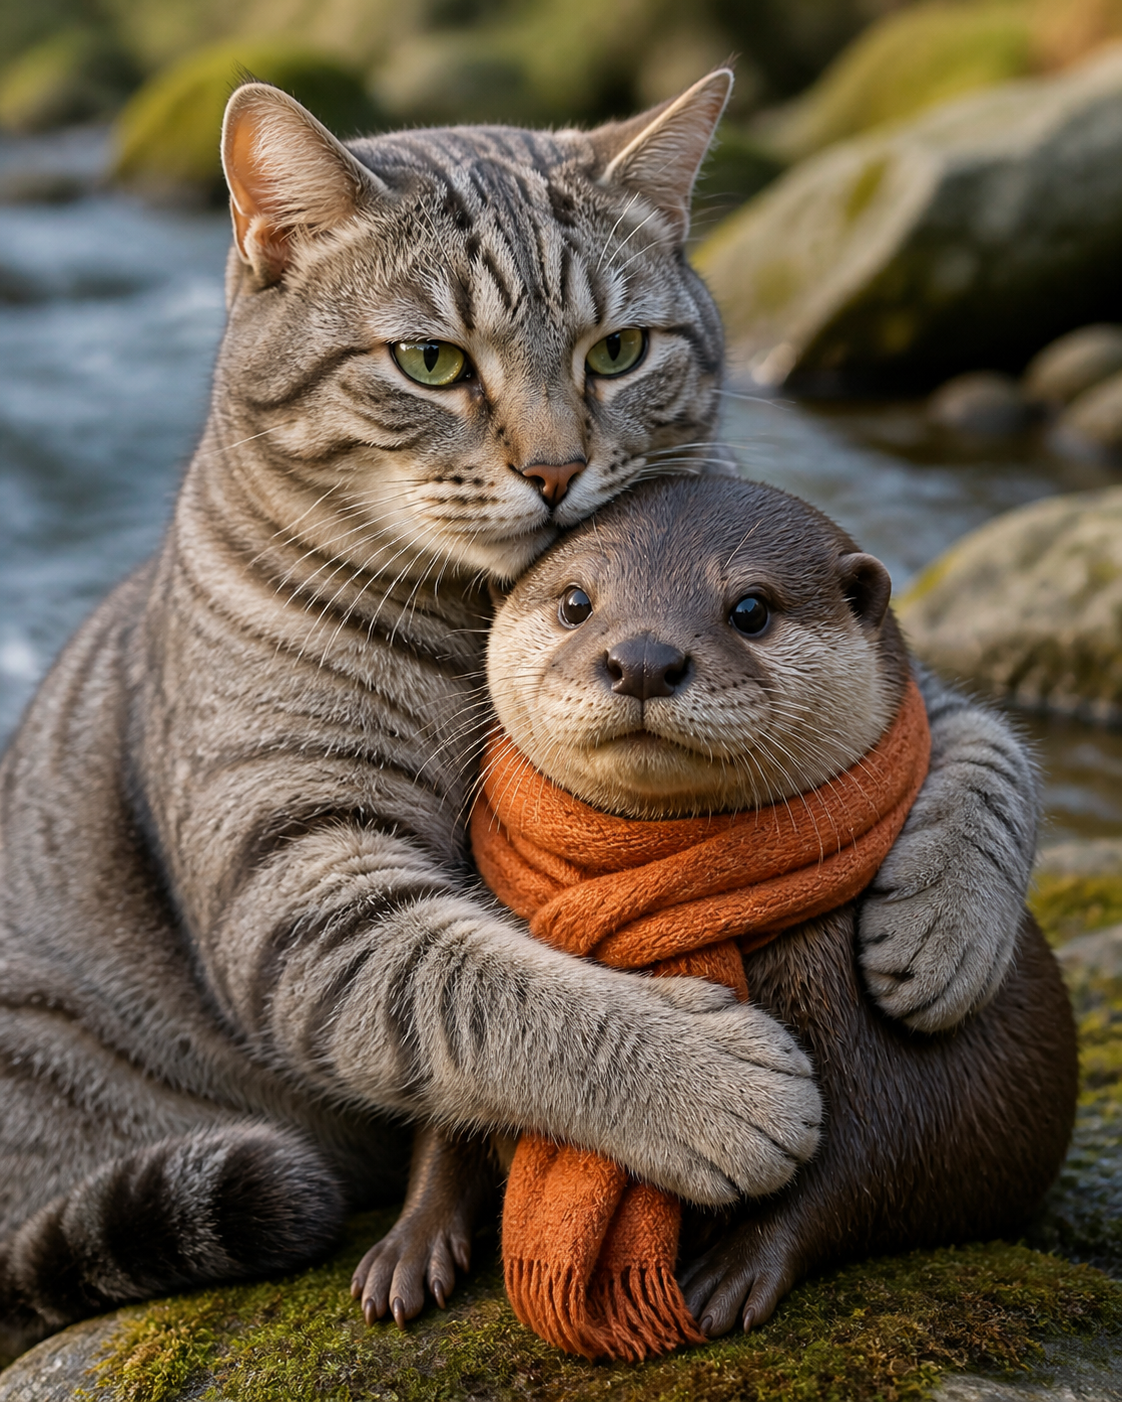

In [27]:
case_number = 34

prompt = use_cases[case_number]

image = generate_image(
    prompt=prompt,
    filename=f"use_case_{case_number}.png"
)

---

## **Text to speech**

In [28]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

# https://platform.openai.com/docs/guides/text-to-speech
response = client.audio.speech.create(
    model="tts-1",
    voice="alloy",
    input="Today is a wonderful day to build something people love!"
)

response.stream_to_file("output.mp3")

/var/folders/5g/9xpg7d6d4114s98tv10y9rgm0000gn/T/ipykernel_82744/3388083089.py:11: DeprecationWarning: Due to a bug, this method doesn't actually stream the response content, `.with_streaming_response.method()` should be used instead
  response.stream_to_file("output.mp3")


In [29]:
# Play the output.mp3 file in the output

from IPython.display import Audio

# Play the audio file
Audio("output.mp3")

In [31]:
# from pathlib import Path
from openai import OpenAI

client = OpenAI()
speech_file_path = "speech.mp3"

with client.audio.speech.with_streaming_response.create(
    model="gpt-4o-mini-tts",
    voice="coral",
    input="Today is a wonderful day to build something people love!",
    instructions="Speak in a cheerful and positive tone.",
) as response:
    response.stream_to_file(speech_file_path)

In [32]:
# Play the speech.mp3 file in the output

from IPython.display import Audio

# Play the audio file
Audio("speech.mp3")

In [33]:
from pathlib import Path
from openai import OpenAI

client = OpenAI()
speech_file_path = "speech.mp3"

with client.audio.speech.with_streaming_response.create(
    model="gpt-4o-mini-tts",
    voice="coral",
    input="Today is a wonderful day to build something people love!",
    instructions="Speak in a sad and demotivated tone.",
) as response:
    response.stream_to_file(speech_file_path)

# Play the speech.mp3 file in the output

from IPython.display import Audio

# Play the audio file
Audio("speech.mp3")

# Speech to Text

In [34]:
# https://platform.openai.com/docs/guides/speech-to-text

from openai import OpenAI
client = OpenAI()

audio_file= open("speech.mp3", "rb")

transcription = client.audio.transcriptions.create(
    model="gpt-4o-transcribe",
    file=audio_file
)

print(transcription.text)

Today is a wonderful day to build something people love.


In [35]:
# https://platform.openai.com/docs/guides/speech-to-text
from openai import OpenAI

client = OpenAI()
audio_file= open("Monster Manor by Sora 2.mp4", "rb")

transcription = client.audio.transcriptions.create(
    model="gpt-4o-transcribe",
    file=audio_file
)

print(transcription.text)

In a small town outside Candy Corn Village, in the cul-de-sac at the end of Pumpkin Patch Lane, lies a home of retired ghouls, ghosts, and goblins in... Monster Manor. Okay, everyone, gather around. Tonight's the night! Halloween is obviously our biggest night. Everyone comes for candy, we smile, we wave, but we do not show off our magic. No one can know about our special powers. I'd like to give a big spooky shout-out to Werewolf for decorating the house, and another spooky shout-out to Frankenstein for making sure we have our correct costumes. I love Halloween. On other days, people run away from me. But on Halloween, everyone is very nice. Remember, it is kosher to wear our costumes today, but we still have to hide our secret powers and special tricks. I'm looking at you, Jack-O-Lantern. I've got hella powers, but witch says we're not allowed to show anyone or we'll freak them out. And of course, a spooky shout-out to Count Dracula for picking up our Halloween candy. Okay, so the th